In [ ]:
# # CodeOrbit Internship — Task 3
# ## Simple Linear Regression Using Python

# **Internship:** CodeOrbit Tech — Data Science Internship  
# **Project:** Titanic Dataset Analysis  
# **Student:** Ritesh Kumar Singh

# ### Objective
# To build a simple linear regression model using Python and Scikit-learn, make predictions, evaluate model performance, and visualize the results.

# ### Tools and Libraries
# - Python
# - Pandas and NumPy
# - Matplotlib
# - Scikit-learn

# ### Methodology
# 1. Load the cleaned Titanic dataset.
# 2. Select a feature and a numerical target.
# 3. Split the dataset into training and testing sets.
# 4. Train a linear regression model.
# 5. Evaluate predictions using regression metrics.
# 6. Visualize the results and document the findings.

In [1]:
# Import libraries required for data analysis and machine learning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import tools for training and evaluating the model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the cleaned Titanic dataset
df = pd.read_csv(
      r"D:\CodeOrbit_Titanic_Cleaned.csv"
)

# Display the dataset size and first five rows
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


In [2]:
# Select Age as the input feature (X)
# Select Fare as the numerical target (y)
# Keep only the columns needed for this model
model_data = df[["Age", "Fare"]].copy()

# Remove rows where either selected value is missing
model_data = model_data.dropna()

# Separate the input feature and target variable
X = model_data[["Age"]]
y = model_data["Fare"]

# Display the number of records used
print("Records used:", len(model_data))
print("Input feature: Age")
print("Target variable: Fare")

Records used: 891
Input feature: Age
Target variable: Fare


In [3]:
# Use 80% of the records to train the model
# Reserve 20% for testing its predictions
# random_state ensures the same split can be reproduced
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Display the training and testing dataset sizes
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 712
Testing records: 179


In [4]:
# Create a simple linear regression model
model = LinearRegression()

# Train the model using the training data
model.fit(X_train, y_train)

# Display the learned regression equation
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

print("Model training completed successfully!")

Slope: 0.36205243579534524
Intercept: 22.01285000657193
Model training completed successfully!


In [5]:
# Predict fares for the testing records
y_pred = model.predict(X_test)

# Compare actual fares with predicted fares
results = pd.DataFrame({
    "Actual Fare": y_test.values,
    "Predicted Fare": y_pred
})

# Display the first ten comparisons
display(results.head(10))

,Actual Fare,Predicted Fare
0,15.2458,32.150318
1,10.5000,33.236476
2,7.9250,29.253899
3,33.0000,24.185165
4,11.2417,27.081584
5,78.8500,31.426213
6,7.7500,32.150318
7,18.0000,27.805689
8,7.7500,27.805689
9,26.2833,28.891846


In [6]:
# Calculate Mean Absolute Error (MAE)
mae = mean_absolute_error(y_test, y_pred)

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)

# Calculate Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)

# Calculate R-squared score
r2 = r2_score(y_test, y_pred)

# Print all evaluation results
print("Model Evaluation Results")
print("------------------------")
print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Model Evaluation Results
------------------------
MAE:  25.45
MSE:  1524.64
RMSE: 39.05
R² Score: 0.0147


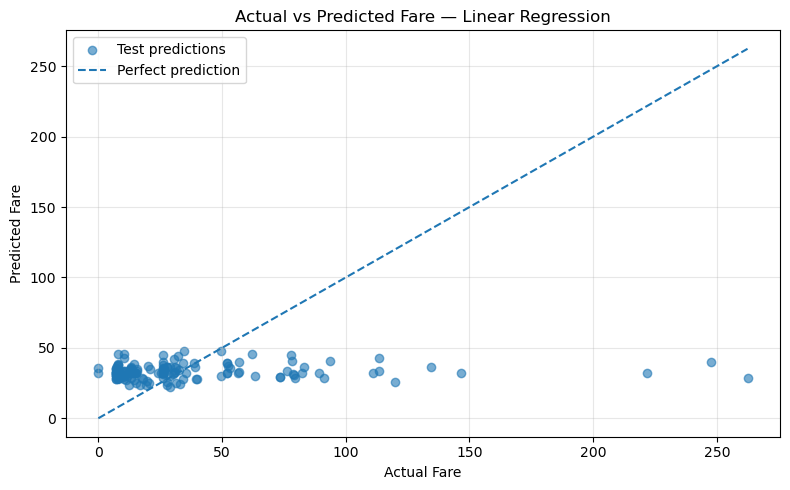

In [7]:
# Plot actual fares against the model's predictions
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.6, label="Test predictions")

# Add a reference line representing perfect predictions
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], linestyle="--",
         label="Perfect prediction")

# Add chart labels and title
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Fare — Linear Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the chart for the project submission
plt.savefig("Task3_Actual_vs_Predicted.png", dpi=300)
plt.show()

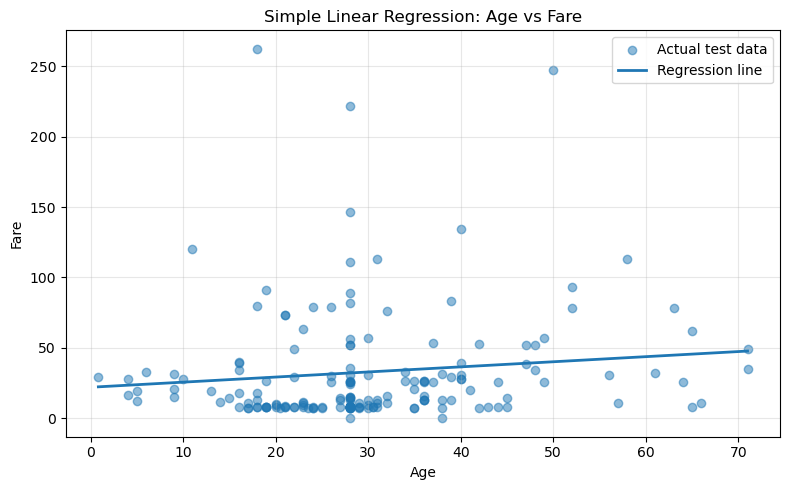

In [8]:
# Plot the original Age and Fare observations
plt.figure(figsize=(8, 5))
plt.scatter(X_test["Age"], y_test, alpha=0.5,
            label="Actual test data")

# Sort ages so the regression line is drawn smoothly
sorted_indices = np.argsort(X_test["Age"].values)
sorted_ages = X_test["Age"].values[sorted_indices]
sorted_predictions = y_pred[sorted_indices]

# Draw the fitted regression line
plt.plot(sorted_ages, sorted_predictions,
         linewidth=2, label="Regression line")

# Add labels, title, and legend
plt.xlabel("Age")
plt.ylabel("Fare")
plt.title("Simple Linear Regression: Age vs Fare")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the visualization
plt.savefig("Task3_Regression_Line.png", dpi=300)
plt.show()

In [9]:
# Store actual and predicted fares in a CSV file
results.to_csv("CodeOrbit_Task3_Predictions.csv", index=False)

# Print confirmation after saving the file
print("Prediction results saved successfully!")

Prediction results saved successfully!


# ## Conclusion

# In this task, I implemented a Simple Linear Regression model using Python and Scikit-learn. I used Age as the input feature and Fare as the target variable. I split the data into training and testing sets, trained the model, generated predictions, and evaluated its performance using MAE, MSE, RMSE, and R².

# I also created visualizations to compare actual and predicted fares and to display the regression line.

# **Limitation:** Age alone may not explain passenger fares well. Fare can depend on passenger class, ticket type, and other factors. The model is a beginner learning exercise and should not be used for real-world fare predictions without further analysis.

In [11]:
# Save the trained model to a file
import joblib

joblib.dump(model, "CodeOrbit_Task3_Linear_Regression.pkl")

print("Trained model saved successfully!")

Trained model saved successfully!
